# Parametric Density Estimation and Clustering

Gordon Richards (2016, 2018, 2020, 2022, 2024) based on materials from Vanderplas, Leighly, Thibert, and Ivezic 4.4, 6.3, 6.4, 6.6.  With updates to my own class from [Stephen Taylor's class at Vanderbilt](https://github.com/VanderbiltAstronomy/astr_8070_s24).

## Contents
* [Parametric density estimation](#one)
* [Expectation Maximization](#two)
* [Clustering](#three)
* [Aside: Scalers](#four)
* [Aside: Pipelines](#five)
* [DBSCAN](#six)
* [Hierarchical Clustering](#seven)
* [Correlation Functions](#eight)

## Parametric Density Estimation <a class="anchor" id="one"></a>

### Gaussian Mixture Models (GMM)

KDE centers each bin (or rather, kernel) at each point.  In a [**mixture model**](https://en.wikipedia.org/wiki/Mixture_model) we don't use a kernel for each data point, but rather we fit for the ***locations of the kernels*** in addition to the width. So a mixture model is sort of a hybrid between a tradtional (fixed bin location/size) histogram and KDE. 

- Using lots of kernels (maybe even more than the BIC score suggests) may make sense if you just want to provide an accurate description of the data (as in density estimation).  
- Using fewer kernels makes mixture models more like clustering (later today), where the suggestion is still to use many kernels in order to divide the sample into real clusters and "background".

Gaussians are the most commonly used components for mixture models.  So, the pdf is modeled by a sum of Gaussians:
$$p(x) = \sum_{k=1}^N \alpha_k \mathscr{N}(x|\mu_k,\Sigma_k),$$
where $\alpha_k$ are the "mixing coefficients" with $0\le \alpha_k \le 1$ and $\sum_{k=1}^N \alpha_k = 1$.

We can solve for the parameters using maximum likelihood analyis as we have discussed previously.
However, this can be complicated in multiple dimensions, requiring the use of [**Expectation Maximization (EM)**](https://en.wikipedia.org/wiki/Expectation%E2%80%93maximization_algorithm) methods (see textbook for details).

Ivezic Figure 4.2 (next cell) provides an example in 1-D.

In [3]:
# Ivezic v2, Figure 4.2
# License: BSD
#   The figure produced by this code is published in the textbook
#   "Statistics, Data Mining, and Machine Learning in Astronomy" (2013)
#   For more information, see http://astroML.github.com
#   To report a bug or issue, use the following forum:
#    https://groups.google.com/forum/#!forum/astroml-general
from matplotlib import pyplot as plt
import numpy as np
from sklearn.mixture import GaussianMixture

if not hasattr(np, "in1d"):
    np.in1d = np.isin

#----------------------------------------------------------------------
# This function adjusts matplotlib settings for a uniform feel in the textbook.
# Note that with usetex=True, fonts are rendered with LaTeX.  This may
# result in an error if LaTeX is not installed on your system.  In that case,
# you can set usetex to False.
if "setup_text_plots" not in globals():
    from astroML.plotting import setup_text_plots
setup_text_plots(fontsize=8, usetex=False)

#------------------------------------------------------------
# Set up the dataset.
#  We'll create our dataset by drawing samples from Gaussians.

random_state = np.random.RandomState(seed=1)

X = np.concatenate([random_state.normal(-1, 1.5, 350),
                    random_state.normal(0, 1, 500),
                    random_state.normal(3, 0.5, 150)]).reshape(-1, 1)

#------------------------------------------------------------
# Learn the best-fit GaussianMixture models
#  Here we'll use scikit-learn's GaussianMixture model. The fit() method
#  uses an Expectation-Maximization approach to find the best
#  mixture of Gaussians for the data

# fit models with 1-10 components
N = np.arange(1, 11)
models = [None for i in range(len(N))]

for i in range(len(N)):
    models[i] = GaussianMixture(N[i]).fit(X)

# compute the AIC and the BIC
AIC = [m.aic(X) for m in models]
BIC = [m.bic(X) for m in models]

#------------------------------------------------------------
# Plot the results
#  We'll use three panels:
#   1) data + best-fit mixture
#   2) AIC and BIC vs number of components
#   3) probability that a point came from each component

fig = plt.figure(figsize=(10, 3.4))
fig.subplots_adjust(left=0.12, right=0.97,
                    bottom=0.21, top=0.9, wspace=0.5)


# plot 1: data + best-fit mixture
ax = fig.add_subplot(131)
M_best = models[np.argmin(AIC)]

x = np.linspace(-6, 6, 1000)
logprob = M_best.score_samples(x.reshape(-1, 1))
responsibilities = M_best.predict_proba(x.reshape(-1, 1))
pdf = np.exp(logprob)
pdf_individual = responsibilities * pdf[:, np.newaxis]

ax.hist(X, 30, density=True, histtype='stepfilled', alpha=0.4)
ax.plot(x, pdf, '-k')
ax.plot(x, pdf_individual, '--k')
ax.text(0.04, 0.96, "Best-fit Mixture",
        ha='left', va='top', transform=ax.transAxes)
ax.set_xlabel('$x$')
ax.set_ylabel('$p(x)$')


# plot 2: AIC and BIC
ax = fig.add_subplot(132)
ax.plot(N, AIC, '-k', label='AIC')
ax.plot(N, BIC, '--k', label='BIC')
ax.set_xlabel('n. components')
ax.set_ylabel('information criterion')
ax.legend(loc=2)


# plot 3: posterior probabilities for each component
ax = fig.add_subplot(133)

p = responsibilities
p = p[:, (1, 0, 2)]  # rearrange order so the plot looks better
p = p.cumsum(1).T

ax.fill_between(x, 0, p[0], color='gray', alpha=0.3)
ax.fill_between(x, p[0], p[1], color='gray', alpha=0.5)
ax.fill_between(x, p[1], 1, color='gray', alpha=0.7)
ax.set_xlim(-6, 6)
ax.set_ylim(0, 1)
ax.set_xlabel('$x$')
ax.set_ylabel(r'$p({\rm class}|x)$')

ax.text(-5, 0.3, 'class 1', rotation='vertical')
ax.text(0, 0.5, 'class 2', rotation='vertical')
ax.text(3, 0.3, 'class 3', rotation='vertical')

plt.show()

ImportError: cannot import name 'neighbors' from 'sklearn' (consider renaming 'c:\\Users\\sarda_hx81cfu\\OneDrive - Drexel University\\Documents\\School\\Fall 2026\\PHYS 440\\sklearn.py' if it has the same name as a library you intended to import)

Here we have some data that we are trying to describe with a mixture of between 1 and 10 Gaussians.  The figure shows an example where 3 Gaussians provides the best fit.

Again, the distribution is modeled as 

$$p(x) = \sum_{k=1}^N \alpha_k \mathscr{N}(x|\mu_k,\Sigma_k),$$
with $0\le \alpha_k \le 1$ controlling the relative height of the Gaussians.  We use Expectation Maximization to determine the properties of each Gaussian ($\alpha$, $\mu_k$,and $\Sigma_k$).

Let's try a simpler example so you can see exactly how to use GMM. We'll fit a two-dimensional distribution composed of two Gaussian distributions using GMMs with varying numbers of components. The BIC will tell us how many components are favored:

In [5]:
# Execute this cell
import numpy as np
from sklearn.mixture import GaussianMixture

X = np.concatenate([np.random.normal(size=(500,2)),
                   np.random.normal(loc=3.0, size=(500,2))]) # 500  points in 2D
BIC = []
for ii in range(1,6):
    gmm = GaussianMixture(ii) # between 1 and 5 components
    gmm.fit(X)
    log_dens = gmm.score(X)
    BIC.append(gmm.bic(X))
    
plt.plot(np.arange(1,6), BIC);
plt.xlabel('Number of components');
plt.ylabel('BIC Score');
plt.show()

ImportError: cannot import name 'neighbors' from 'sklearn' (consider renaming 'c:\\Users\\sarda_hx81cfu\\OneDrive - Drexel University\\Documents\\School\\Fall 2026\\PHYS 440\\sklearn.py' if it has the same name as a library you intended to import)

Do the results make sense?

A typical call to the [Gaussian Mixture Model](http://scikit-learn.org/stable/modules/mixture.html) algorithm looks like this:

In [ ]:
# Execute this cell
import numpy as np
from sklearn.mixture import GaussianMixture

X = np.random.normal(size=(1000,2)) #1000  points in 2D
gmm = GaussianMixture(3) #three components
gmm.fit(X)
log_dens = gmm.score(X)
BIC = gmm.bic(X)

Let's do the 1-D example given using eruption data from "Old Faithful" geyser at Yellowstone National Park.  
[http://www.stat.cmu.edu/~larry/all-of-statistics/=data/faithful.dat](http://www.stat.cmu.edu/~larry/all-of-statistics/=data/faithful.dat).

In [10]:
#eruptions: Eruption time in mins
#waiting: Waiting time to next eruption
import numpy as np
import pandas as pd
df = pd.read_fwf('faithful.dat')
df.head()

,N,eruptions,waiting
0,1,3.600,79
1,2,1.800,54
2,3,3.333,74
3,4,2.283,62
4,5,4.533,85


In [18]:
#Fit Gaussian Mixtures, first in 1-D
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

#First fit Eruptions
gmm1 = GaussianMixture(n_components=2) # 2-component gaussian mixture model
gmm1.fit(df['eruptions'].values[:,None]) # Fit step
xgrid1 = np.linspace(0, 8, 1000) # Make evaluation grid
logprob1 = gmm1.score_samples(xgrid1[:,None]) # Compute log likelihoods on that grid
pdf1 = np.exp(logprob1)
resp1 = gmm1.predict_proba(xgrid1[:,None]) 
pdf_individual1 = resp1 * pdf1[:, np.newaxis] # Compute posterior probabilities for each component

In [19]:

#Then fit waiting
gmm2 = GaussianMixture(n_components=2)
gmm2.fit(df['waiting'].values[:,None])
xgrid2 = np.linspace(30, 120, 1000)
logprob2 = gmm2.score_samples(xgrid2[:,None])
pdf2 = np.exp(logprob2)
resp2 = gmm2.predict_proba(xgrid2[:,None])
pdf_individual2 = resp2 * pdf2[:, np.newaxis]

Text(0.5, 0, 'Waiting')

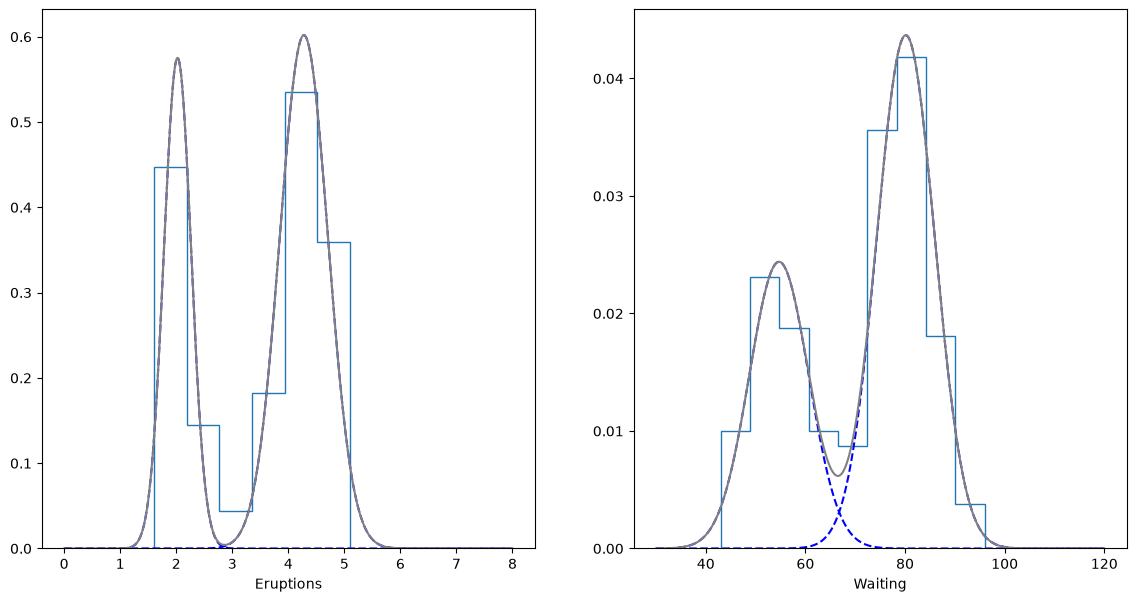

In [22]:
#Make plots
fig = plt.figure(figsize=(14, 7))
ax = fig.add_subplot(121)
plt.hist(df['eruptions'], bins=6, density=True, histtype='step')
plt.plot(xgrid1, pdf_individual1, '--', color='blue')
plt.plot(xgrid1, pdf1, '-', color='gray')
plt.xlabel("Eruptions")

ax = fig.add_subplot(122)
plt.hist(df['waiting'], bins=9, density=True, histtype='step')
plt.plot(xgrid2, pdf_individual2, '--', color='blue')
plt.plot(xgrid2, pdf2, '-', color='gray')
plt.xlabel("Waiting")

Now let's look at the Old Faithful data again, but this time in 2-D.

(40.0, 100.0)

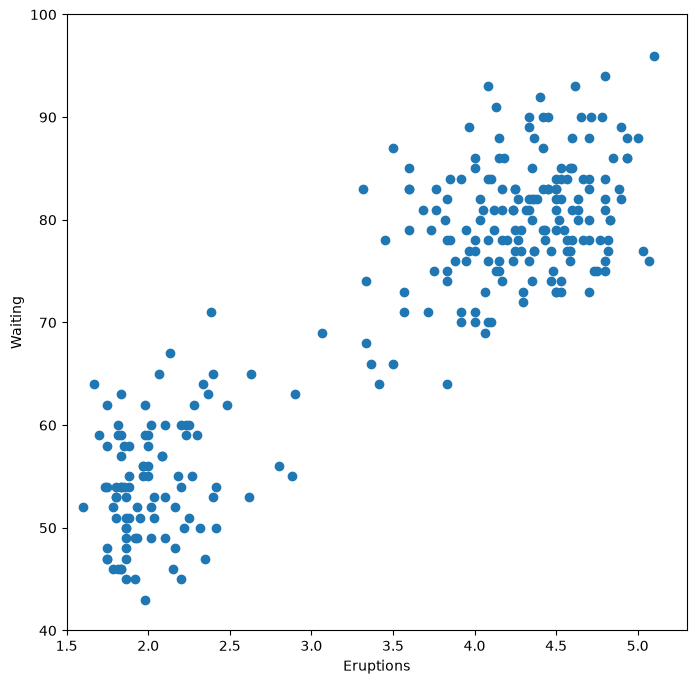

In [23]:
fig = plt.figure(figsize=(8, 8))
plt.scatter(df['eruptions'],df['waiting'])
plt.xlabel('Eruptions')
plt.ylabel('Waiting')
plt.xlim([1.5,5.3])
plt.ylim([40,100])

Now we'll fit both features at the same time (i.e., the $x$ and $y$ axes above).  Note that Scikit-Learn can handle Pandas DataFrames without further conversion.

In [25]:
gmm3 = GaussianMixture(n_components=2)
gmm3.fit(df[['eruptions','waiting']]) #Note no need for "None"

,"n_components n_components: int, default=1The number of mixture components.",2
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'full'
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",1
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None


Once the components have been fit, we can plot the location of the centroids and the "error" ellipses.

In [26]:
#Kludge to fix the bug with draw_ellipse in astroML v1.0
from matplotlib.patches import Ellipse

def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    # find principal components and rotation angle of ellipse
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]

    alpha = 0.5 * np.arctan2(2 * sigma_xy,
                             (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)

    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)

    for scale in scales:
        ax.add_patch(Ellipse((mu[0], mu[1]),
                             width=2 * scale * sigma1, height=2 * scale * sigma2,
                             angle=alpha * 180. / np.pi,
                             **kwargs))

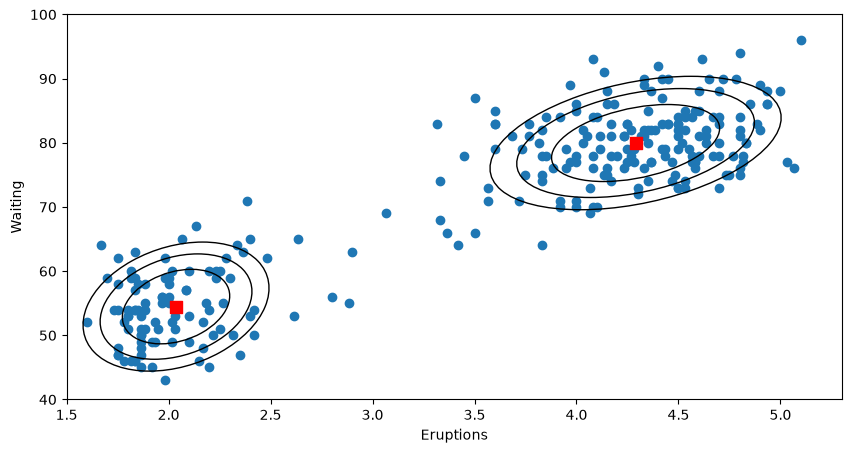

In [27]:
#See cell above

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111)
plt.scatter(df['eruptions'],df['waiting'])
plt.xlabel('Eruptions')
plt.ylabel('Waiting')
plt.xlim([1.5,5.3])
plt.ylim([40,100])

ax.scatter(gmm3.means_[:,0], gmm3.means_[:,1], marker='s', c='red', s=80)
for mu, C, w in zip(gmm3.means_, gmm3.covariances_, gmm3.weights_):
    draw_ellipse(mu, 2*C, scales=[1], ax=ax, fc='none', ec='k') #2 sigma ellipses for each component
#Add a 3-sigma error ellipse 
for mu, C, w in zip(gmm3.means_, gmm3.covariances_, gmm3.weights_):
    draw_ellipse(mu, 3*C, scales=[1], ax=ax, fc='none', ec='k') #3 sigma ellipses for each component
#Add a 1-sigma error ellipse 
for mu, C, w in zip(gmm3.means_, gmm3.covariances_, gmm3.weights_):
    draw_ellipse(mu, 1*C, scales=[1], ax=ax, fc='none', ec='k') #1 sigma ellipses for each component

Ivezic, Figure 6.6 shows another 2-D example.  In the first panel, we have the raw data.  We then try to represent the data with a series of Gaussians.  We allow up to 14 Gaussians and use the AIC/BIC to determine the best choice for this number.  This is shown in the second panel.  Finally, the third panel shows the chosen Gaussians with their centroids and 1-$\sigma$ contours on top of a density plot of our data.

In this case 5 components are required for the best fit.  While it looks like we could do a pretty good job with just 2 components, there does appear to be some "background" that is a high enough level to justify further components.

c:\Users\sarda_hx81cfu\AppData\Local\Programs\Python\Python314\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


@pickle_results: computing results and saving to 'GMM_metallicity.pkl'
1
2
3
4
5
6
7
8
9
10
11
12
13
best fit converged: True
BIC: n_components =  5


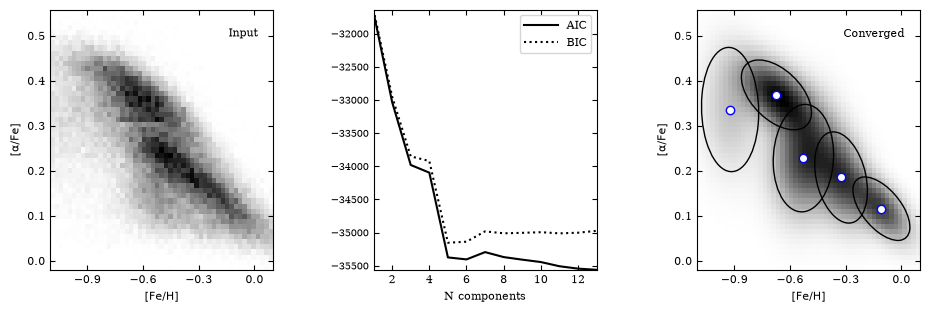

In [28]:
# Execute this cell
# Ivezic, Figure 6.6
# Author: Jake VanderPlas
# License: BSD
#   The figure produced by this code is published in the textbook
#   "Statistics, Data Mining, and Machine Learning in Astronomy" (2013)
#   For more information, see http://astroML.github.com
#   To report a bug or issue, use the following forum:
#    https://groups.google.com/forum/#!forum/astroml-general

from __future__ import print_function

import numpy as np
from matplotlib import pyplot as plt

from sklearn.mixture import GaussianMixture

from astroML.datasets import fetch_sdss_sspp
from astroML.utils.decorators import pickle_results
#See cells above
#from astroML.plotting import draw_ellipse

#----------------------------------------------------------------------
# This function adjusts matplotlib settings for a uniform feel in the textbook.
# Note that with usetex=True, fonts are rendered with LaTeX.  This may
# result in an error if LaTeX is not installed on your system.  In that case,
# you can set usetex to False.
if "setup_text_plots" not in globals():
    from astroML.plotting import setup_text_plots
setup_text_plots(fontsize=8, usetex=False)

#------------------------------------------------------------
# Get the Segue Stellar Parameters Pipeline data
data = fetch_sdss_sspp(cleaned=True)
X = np.vstack([data['FeH'], data['alphFe']]).T

# truncate dataset for speed
X = X[::5]

#------------------------------------------------------------
# Compute GaussianMixture models & AIC/BIC
N = np.arange(1, 14)


@pickle_results("GMM_metallicity.pkl")
def compute_GaussianMixture(N, covariance_type='full', max_iter=1000):
    models = [None for n in N]
    for i in range(len(N)):
        print(N[i])
        models[i] = GaussianMixture(n_components=N[i], max_iter=max_iter,
                                    covariance_type=covariance_type)
        models[i].fit(X)
    return models

models = compute_GaussianMixture(N)

AIC = [m.aic(X) for m in models]
BIC = [m.bic(X) for m in models]

i_best = np.argmin(BIC)
gmm_best = models[i_best]
print("best fit converged:", gmm_best.converged_)
print("BIC: n_components =  %i" % N[i_best])

#------------------------------------------------------------
# compute 2D density
FeH_bins = 51
alphFe_bins = 51
H, FeH_bins, alphFe_bins = np.histogram2d(data['FeH'], data['alphFe'],
                                          (FeH_bins, alphFe_bins))

Xgrid = np.array(list(map(np.ravel,
                          np.meshgrid(0.5 * (FeH_bins[:-1]
                                             + FeH_bins[1:]),
                                      0.5 * (alphFe_bins[:-1]
                                             + alphFe_bins[1:]))))).T
log_dens = gmm_best.score_samples(Xgrid).reshape((51, 51))

#------------------------------------------------------------
# Plot the results
fig = plt.figure(figsize=(10, 4))
fig.subplots_adjust(wspace=0.45,
                    bottom=0.25, top=0.9,
                    left=0.1, right=0.97)

# plot density
ax = fig.add_subplot(131)
ax.imshow(H.T, origin='lower', interpolation='nearest', aspect='auto',
          extent=[FeH_bins[0], FeH_bins[-1],
                  alphFe_bins[0], alphFe_bins[-1]],
          cmap=plt.cm.binary)
ax.set_xlabel(r'$\rm [Fe/H]$')
ax.set_ylabel(r'$\rm [\alpha/Fe]$')
ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
ax.set_xlim(-1.101, 0.101)
ax.text(0.93, 0.93, "Input",
        va='top', ha='right', transform=ax.transAxes)

# plot AIC/BIC
ax = fig.add_subplot(132)
ax.plot(N, AIC, '-k', label='AIC')
ax.plot(N, BIC, ':k', label='BIC')
ax.legend(loc=1)
ax.set_xlabel('N components')
plt.setp(ax.get_yticklabels(), fontsize=7)

# plot best configurations for AIC and BIC
ax = fig.add_subplot(133)
ax.imshow(np.exp(log_dens),
          origin='lower', interpolation='nearest', aspect='auto',
          extent=[FeH_bins[0], FeH_bins[-1],
                  alphFe_bins[0], alphFe_bins[-1]],
          cmap=plt.cm.binary)

ax.scatter(gmm_best.means_[:, 0], gmm_best.means_[:, 1], c='w')
for mu, C, w in zip(gmm_best.means_, gmm_best.covariances_, gmm_best.weights_):
    draw_ellipse(mu, C, scales=[1.5], ax=ax, fc='none', ec='k')

ax.text(0.93, 0.93, "Converged",
        va='top', ha='right', transform=ax.transAxes)

ax.set_xlim(-1.101, 0.101)
ax.set_ylim(alphFe_bins[0], alphFe_bins[-1])
ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
ax.set_xlabel(r'$\rm [Fe/H]$')
ax.set_ylabel(r'$\rm [\alpha/Fe]$')

plt.show()

Talk about how to use this to do outlier finding.  Convolve with errors of unknown object.

Lastly, let's look at a 2-D case where we are using GMM more to characterize the data than to find clusters.  

@pickle_results: computing results and saving to 'great_wall_GMM.pkl'
converged: True


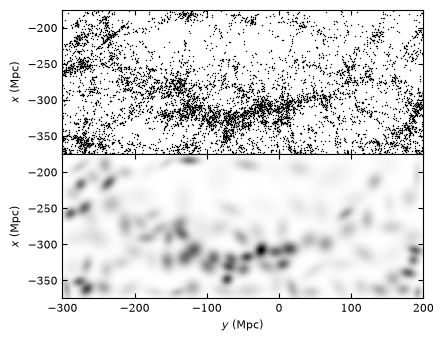

In [29]:
# Ivezic v2, Figure 6.7
# Author: Jake VanderPlas
# License: BSD
#   The figure produced by this code is published in the textbook
#   "Statistics, Data Mining, and Machine Learning in Astronomy" (2013)
#   For more information, see http://astroML.github.com
#   To report a bug or issue, use the following forum:
#    https://groups.google.com/forum/#!forum/astroml-general

from __future__ import print_function

import numpy as np
from matplotlib import pyplot as plt

from sklearn.mixture import GaussianMixture
from astroML.datasets import fetch_great_wall
from astroML.utils.decorators import pickle_results

#----------------------------------------------------------------------
# This function adjusts matplotlib settings for a uniform feel in the textbook.
# Note that with usetex=True, fonts are rendered with LaTeX.  This may
# result in an error if LaTeX is not installed on your system.  In that case,
# you can set usetex to False.
if "setup_text_plots" not in globals():
    from astroML.plotting import setup_text_plots
setup_text_plots(fontsize=8, usetex=False)

#------------------------------------------------------------
# load great wall data
X = fetch_great_wall()


#------------------------------------------------------------
# Create a function which will save the results to a pickle file
#  for large number of clusters, computation will take a long time!
@pickle_results('great_wall_GMM.pkl')
def compute_GMM(n_clusters, max_iter=1000, tol=3, covariance_type='full'):
    clf = GaussianMixture(n_clusters, covariance_type=covariance_type,
                          max_iter=max_iter, tol=tol, random_state=0)
    clf.fit(X)
    print("converged:", clf.converged_)
    return clf

#------------------------------------------------------------
# Compute a grid on which to evaluate the result
Nx = 100
Ny = 250
xmin, xmax = (-375, -175)
ymin, ymax = (-300, 200)

#Xgrid = np.vstack(map(np.ravel, np.meshgrid(np.linspace(xmin, xmax, Nx), np.linspace(ymin, ymax, Ny)))).T
Xgrid = np.vstack([np.ravel(arr) for arr in np.meshgrid(np.linspace(xmin, xmax, Nx), np.linspace(ymin, ymax, Ny))]) .T


#------------------------------------------------------------
# Compute the results
#
# we'll use 100 clusters.  In practice, one should cross-validate
# with AIC and BIC to settle on the correct number of clusters.
clf = compute_GMM(n_clusters=100)
log_dens = clf.score_samples(Xgrid).reshape(Ny, Nx)

#------------------------------------------------------------
# Plot the results
fig = plt.figure(figsize=(5, 3.75))
fig.subplots_adjust(hspace=0, left=0.08, right=0.95, bottom=0.13, top=0.9)

ax = fig.add_subplot(211, aspect='equal')
ax.scatter(X[:, 1], X[:, 0], s=1, lw=0, c='k')

ax.set_xlim(ymin, ymax)
ax.set_ylim(xmin, xmax)

ax.xaxis.set_major_formatter(plt.NullFormatter())
plt.ylabel(r'$x\ {\rm (Mpc)}$')

ax = fig.add_subplot(212, aspect='equal')
ax.imshow(np.exp(log_dens.T), origin='lower', cmap=plt.cm.binary,
          extent=[ymin, ymax, xmin, xmax])
ax.set_xlabel(r'$y\ {\rm (Mpc)}$')
ax.set_ylabel(r'$x\ {\rm (Mpc)}$')

plt.show()

Note that this is very different than the non-parametric density estimates.  The advantage is that we now have a *model*.  This model can be stored very compactly with just a few numbers, unlike the KDE or KNN maps which require a floating point number for each grid point.  

One thing that you might imagine doing with this is subtracting the model from the data and looking for interesting things among the residuals.

---

## Clustering  <a class="anchor" id="three"></a>

> [Clustering](https://en.wikipedia.org/wiki/Cluster_analysis) algorithms attempt to group together like objects in a data set.  

This process allows us to put new objects into the resulting classes and to identify rare objects that do not fit any particular mold.  **Clustering is inherently an "unsupervised" process** as we do not know the classification of the objects.  Since we have no metric for determining when we are right, it is a bit of a dark art, but it also can be very powerful.  Scikit-Learn's clustering suite is summarized at [http://scikit-learn.org/stable/modules/clustering.html](http://scikit-learn.org/stable/modules/clustering.html).

### $K$-Means Clustering

We start with [$K$-means clustering](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), which is one of the simplest methods.  $K$-means seeks to minimize the following

$$\sum_{k=1}^{K}\sum_{i\in C_k}||x_i - \mu_k||^2$$

where $\mu_k = \frac{1}{N_k}\sum_{i\in C_k} x_i$

This says to
  * Take every object in class $C_k$ (as determined by which centroid it is closest to, specifically $C_k(x_i) = \arg \min_k ||x_i-\mu_k||)$
  * Compute the mean of the objects in that class
  * Subtract that mean from each member of that class and square the norm
  * Do that for each class and sum
  * Shift the centroids of the *pre-determined* number of classes until this sum is minimized
  * Do this multiple times with different starting centroids and take the result with the minimum sum

A typical call will look something like this

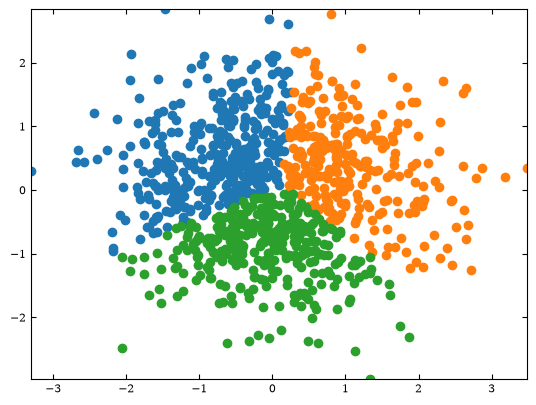

In [41]:
# Execute this cell
import numpy as np
from sklearn.cluster import KMeans

X = np.random.normal(size=(1000,2)) #1000 points in 2D
clf = KMeans(n_clusters=3) #Try 3 clusters to start with
clf.fit(X)
centers=clf.cluster_centers_ #location of the clusters
labels=clf.predict(X) #labels for each of the points

# plot the data color-coded by cluster id
colors = ['C0', 'C1', 'C2']
for ii in range(3):
    plt.scatter(X[labels==ii,0], X[labels==ii,1], color=colors[ii])
    
# To get some information on these try:
# KMeans?
# help(clf)

Here is an example with the same data that we used for GMM.  Note how the background shifts the centroids from what you might expect.  So, the mixture model might work better in this case.

However, one might consider running the K-means algorithm in order to find a suitable initialization for GMM. 

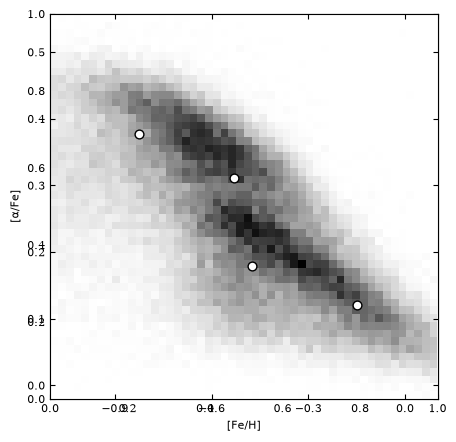

In [31]:
# Ivezic v2, Figure 6.13
# Author: Jake VanderPlas
# License: BSD
#   The figure produced by this code is published in the textbook
#   "Statistics, Data Mining, and Machine Learning in Astronomy" (2013)
#   For more information, see http://astroML.github.com
#   To report a bug or issue, use the following forum:
#    https://groups.google.com/forum/#!forum/astroml-general
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Ellipse
from scipy.stats import norm

from sklearn.cluster import KMeans
from sklearn import preprocessing

from astroML.datasets import fetch_sdss_sspp

#----------------------------------------------------------------------
# This function adjusts matplotlib settings for a uniform feel in the textbook.
# Note that with usetex=True, fonts are rendered with LaTeX.  This may
# result in an error if LaTeX is not installed on your system.  In that case,
# you can set usetex to False.
if "setup_text_plots" not in globals():
    from astroML.plotting import setup_text_plots
setup_text_plots(fontsize=8, usetex=False)

#------------------------------------------------------------
# Get data
data = fetch_sdss_sspp(cleaned=True)
X = np.vstack([data['FeH'], data['alphFe']]).T

# truncate dataset for speed
X = X[::5]

#------------------------------------------------------------
# Compute a 2D histogram  of the input
H, FeH_bins, alphFe_bins = np.histogram2d(data['FeH'], data['alphFe'], 50)

#------------------------------------------------------------
# Compute the KMeans clustering
n_clusters = 4

scaler = preprocessing.StandardScaler()
clf = KMeans(n_clusters)
clf.fit(scaler.fit_transform(X))

#------------------------------------------------------------
# Visualize the results
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot()

# plot density
ax = plt.axes()
ax.imshow(H.T, origin='lower', interpolation='nearest', aspect='auto',
          extent=[FeH_bins[0], FeH_bins[-1],
                  alphFe_bins[0], alphFe_bins[-1]],
          cmap=plt.cm.binary)

# plot cluster centers
cluster_centers = scaler.inverse_transform(clf.cluster_centers_)
ax.scatter(cluster_centers[:, 0], cluster_centers[:, 1],
           s=40, c='w', edgecolors='k')

# plot cluster boundaries
FeH_centers = 0.5 * (FeH_bins[1:] + FeH_bins[:-1])
alphFe_centers = 0.5 * (alphFe_bins[1:] + alphFe_bins[:-1])

Xgrid = np.meshgrid(FeH_centers, alphFe_centers)
Xgrid = np.array(Xgrid).reshape((2, 50 * 50)).T

#H = clf.predict(scaler.transform(Xgrid)).reshape((50, 50))

#for i in range(n_clusters):
#    Hcp = H.copy()
#    flag = (Hcp == i)
#    Hcp[flag] = 1
#    Hcp[~flag] = 0

#    ax.contour(FeH_centers, alphFe_centers, Hcp, [-0.5, 0.5], linewidths=1, colors='k')

ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
ax.set_xlim(-1.101, 0.101)
ax.set_ylim(alphFe_bins[0], alphFe_bins[-1])

ax.set_xlabel(r'$\rm [Fe/H]$')
ax.set_ylabel(r'$\rm [\alpha/Fe]$')

plt.show()

A few things to note
* This was supposed to show the boundaries between the clusters, but it isn't working.  See another example below.
* We scaled the data (subtracted the mean and scaling to unit variance) using `StandardScaler()` before running K-Means
* We had to *un*scale the data to plot the centers
* Plotting the cluster boundaries is not straightforward, but this gives you an example to work with

Lastly, K-means is great for idealized data (roughly spherical clusters of similar density), but it has some problems with more complicated situations.  The following situation may not be realistic, but it illustrates where we can run into problems.

In [46]:
#Create two samples that are not spherically symmetric and try Kmeans.
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=1000, noise=0.1, random_state=42)

In [48]:
clf = KMeans(n_clusters=2) #Try 2 clusters as there are clearly 2 by eye
clf.fit(X)
centers=clf.cluster_centers_ #location of the clusters
labels=clf.predict(X) #labels for each of the points

(-1.0, 1.5)

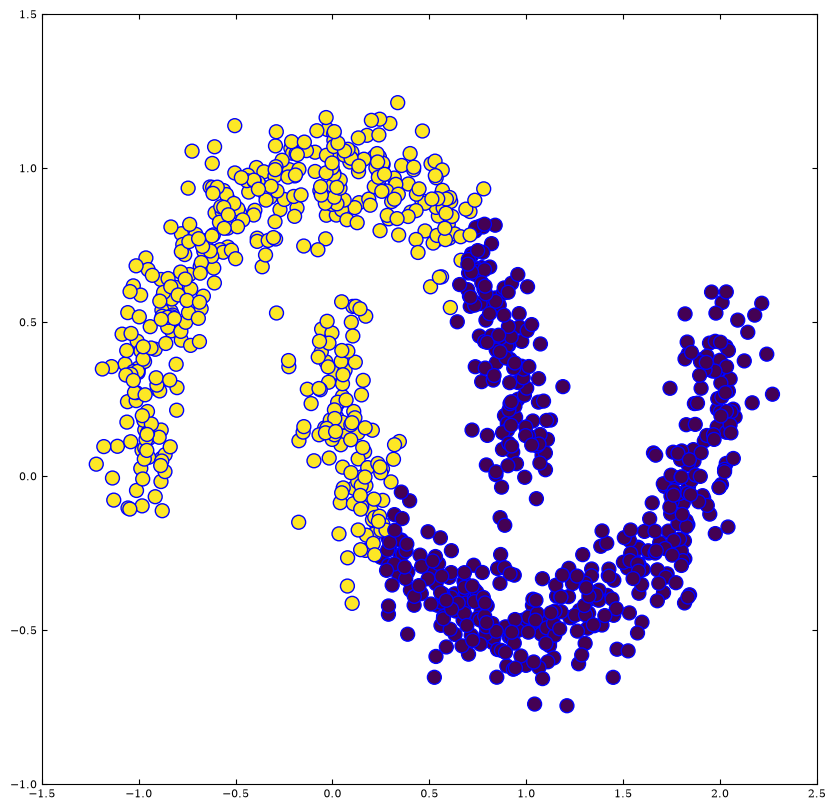

In [49]:
plt.figure(figsize=(10,10))
plt.scatter(X[:, 0], X[:, 1], s=100, c=labels)

plt.xlim(-1.5, 2.5)
plt.ylim(-1.0, 1.5)

Not so great.  

### DBSCAN  <a class="anchor" id="six"></a>

Let's try another algorithm, [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.dbscan.html), which is "A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise".  This isn't discussed in the Ivezic book, but the link will take you to the description given in Scikit Learn.

In [50]:
def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    cores = dbscan.components_
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]
    
    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Paired")
    plt.scatter(cores[:, 0], cores[:, 1], marker='*', s=20, c=dbscan.labels_[core_mask])
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100)
    plt.scatter(non_cores[:, 0], non_cores[:, 1], c=dbscan.labels_[non_core_mask], marker=".")
    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)
    #plt.title("eps={:.2f}, min_samples={}".format(dbscan.eps, dbscan.min_samples), fontsize=14)

Note that DBSCAN is *very* sensitive to these parameters.  Here we'll just do trial and error.  Try a few values of `eps` between 0.05 and 0.2 and `min_samples` between 3 and 10.

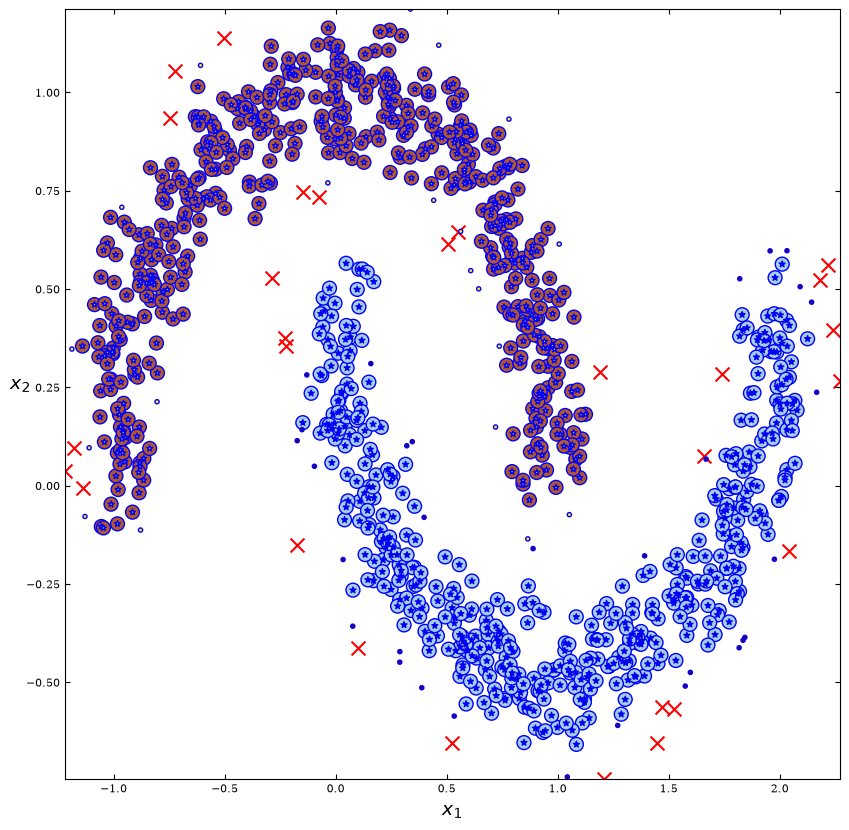

In [52]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.1, min_samples=5)
dbscan.fit(X)

plt.figure(figsize=(10, 10))
plot_dbscan(dbscan, X, size=100)

Not only is DBSCAN telling you which cluster each object belongs to, it is also "outliers" (denoted by the red crosses), which is another important use of clustering algorithms.

---

## Hierarchical Clustering  <a class="anchor" id="seven"></a>

In [Hierarchical Clustering](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html), we don't specify the number of clusters ahead of time, we start with $N$ clusters representing each data point.  Then the most similar clusters are joined together, the process repeating until some threshhold is reached.  Actually the process can go in the other direction as well.  What results is called a **dendrogram**, an example of which is shown below.

![](https://ramaanathan.github.io/PSU_STAT505_MVA/L14_Clustering/Lesson14_Clustering_files/figure-markdown_github/unnamed-chunk-1-1.png)

Clusters are merged at each step according to which are "nearest" to each other---where the definition of nearest needs to be specified.  A typical choice results in what is called a **minimum spanning tree** (which can be quite slow for large data sets).  Some threshhold needs to be specified to tell the process where to stop (e.g., we are going to treat the green and red objects in the example above as separate clusters).  

![Here is an illustration](https://www.statisticshowto.com/wp-content/uploads/2016/11/clustergram.png)


Below is an example call.

In [53]:
# Execute this cell
import numpy
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.neighbors import kneighbors_graph

X = np.random.random((1000,2))
G = kneighbors_graph(X, n_neighbors=10, mode='distance')
T = minimum_spanning_tree(G)

Summary of Chapter 6 methods from Ivezic Table 6.1 

|Method          |Accuracy|Interpretability|Simplicity|Speed|
|----------------|--------|----------------|----------|-----|
|K-nearest Neighbor| H | H | H | M |
|Kernel Density Estimation| H | H | H | H |
|Gaussian Mixture Models| H | M | M | M |
|Extreme Deconvolution| H | H | M | M |
||||||
|K-Means| L | M | H | M |
|Max-radius minimization| L | M | M | M |
|Mean shift| M | H | H | M |
|Hierarchical Clustering| H | L | L | L |